<img src="./logo_UTN.svg" align="right" width="150" /> 

### Teoría de Circuitos II

# Trabajo Practico de Laboratorio II

Autor: *Olea Gasalla Ignacio Ezequiel*

*Fecha de entrega: sábado 31 de octubre de 2026*

#### **Consigna** 
<img src="./consigna_1.png" /> 

##### **Bonus**:
<img src="./consigna_2.png" /> 

### Pre-Lab
 Se construyeron los filtros digitales correspondientes pedidos: se eligió crear un *Filtro Pasa Bajos del tipo FIR* y un *Filtro Notch del tipo IIR*. 
 En el siguiente bloque de código se muestra lo que se obtuvo de ello con las respectivas especificaciones de cada filtro y el gráfico de su transferencia respecto a la frecuencia:

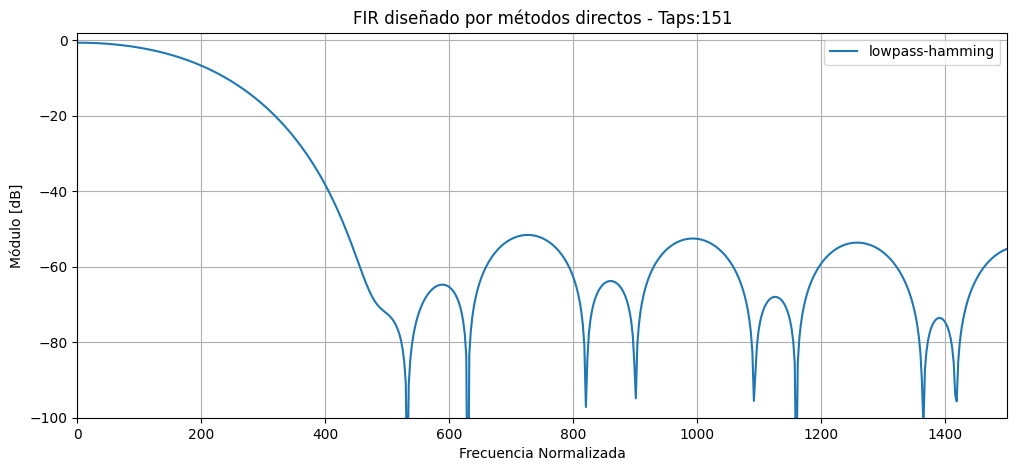

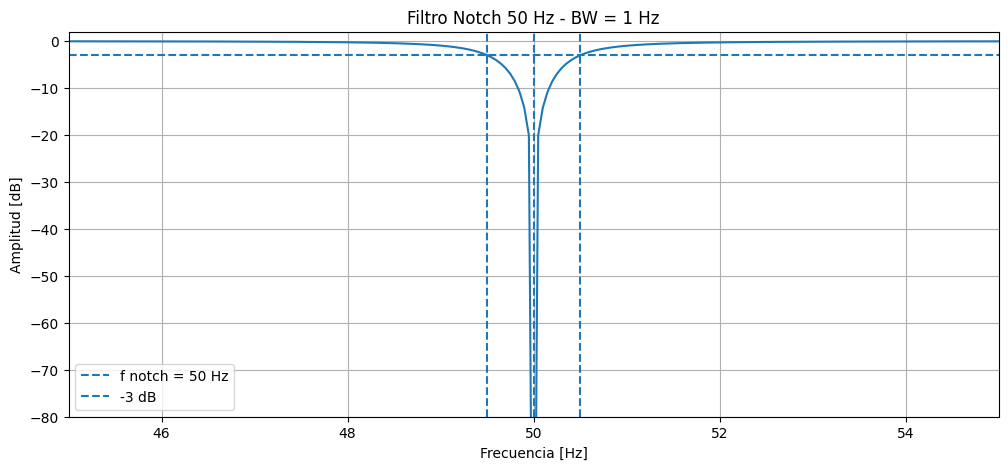

In [76]:
####################################
#           LP Cheby FIR
####################################

# frecuencia de muestreo normalizada
fs = 20*10**3
# tamaño de la respuesta al impulso
cant_coef = 151

# Especificaciones
fpass = 100       # Hz
ripple = 1        # dB
fstop = 300       # Hz
attenuation = 60  # dB

f_predist = 60    #Hz

# construyo la plantilla de requerimientos
frecs = [0.0,  fpass + f_predist,   fstop - f_predist ,   fs/2]
gains = [0,   -ripple, -attenuation,   -np.inf] # dB

gains = 10**(np.array(gains)/20)

# FIR design
num_hm = sig.firwin2(cant_coef, frecs, gains , window='hamming', fs=fs)

# Obtenemos la transferencia de nuestro FIR apartir de los coeficientes
ww, hh = sig.freqz( num_hm , 1.0 , worN=4096 , fs=fs ) 
hh_LP = 20 * np.log10(np.abs(hh))

plt.figure(figsize=(12, 5))
plt.plot(ww, hh_LP, label='lowpass-hamming')
plt.xlim(0, 1500)
plt.ylim(-100, 2)
plt.xlabel('Frecuencia Normalizada')
plt.ylabel('Módulo [dB]')
plt.title('FIR diseñado por métodos directos - Taps:151')
plt.grid(True)
plt.legend()
plt.show()

# print(num_hm)



####################################
#         Notch Cheby IIR
####################################

# Especificaciones
f0 = 50.0
BW = 1.0
fs_muestreo = 20000.0
Q = f0 / BW # Factor de calidad

# Filtro notch
b, a = sig.iirnotch(f0, Q, fs=fs_muestreo)

sos = sig.tf2sos(b, a)
w, h = sig.sosfreqz(sos,worN=200000,fs=fs_muestreo)

plt.figure(figsize=(12, 5))
plt.plot(w, 20*np.log10(np.maximum(np.abs(h), 1e-8)))
plt.axvline(f0, linestyle='--', label='f notch = 50 Hz')
# Bordes de BW de 1 Hz
plt.axvline(49.5, linestyle='--')
plt.axvline(50.5, linestyle='--')
plt.axhline(-3, linestyle='--', label='-3 dB')
plt.xlim(45, 55)
plt.ylim(-80, 2)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.title('Filtro Notch 50 Hz - BW = 1 Hz')
plt.grid(True)
plt.legend()
plt.show()

# print(sos)

### Análisis de los datos
 En los siguientes bloques de código se muestran un gráfico de lo obtenido en la práctica, siendo el tercer gráfico un Pasa Todo (tambien llamado como "NONE" en el código) que tiene una atenuación por lo que el objetivo será obtener la respuesta verdadera del Filtro Pasa Bajos FIR y del Filtro Notch IIR apartir de los datos obtenidos en la práctica:

In [77]:
import sympy as sp
import numpy as np
import scipy.signal as sig
from scipy.signal.windows import hamming
import matplotlib.pyplot as plt
from pytc2.sistemas_lineales import plot_plantilla, group_delay

LP     = 0
NOTCH  = 1
NONE   = 2

# 34	Sweep - Function 2"
# 35	Vac vs Frequency
# 36	X (Hz)","Ch-1 (dBr)
data_none_vac  =np.genfromtxt('none.csv' ,delimiter=',', skip_header=36 )
data_lp_vac    =np.genfromtxt('lp.csv'   ,delimiter=',', skip_header=106)
data_notch_vac =np.genfromtxt('notch.csv',delimiter=',', skip_header=106)


# f =[ LP_VAC , NOTCH_VAC , NONE_VAC ]
f   =[ data_lp_vac[:, 0] , data_notch_vac[:, 0] , data_none_vac[:, 0] ]
ch1 =[ data_lp_vac[:, 1] , data_notch_vac[:, 1] , data_none_vac[:, 1] ]


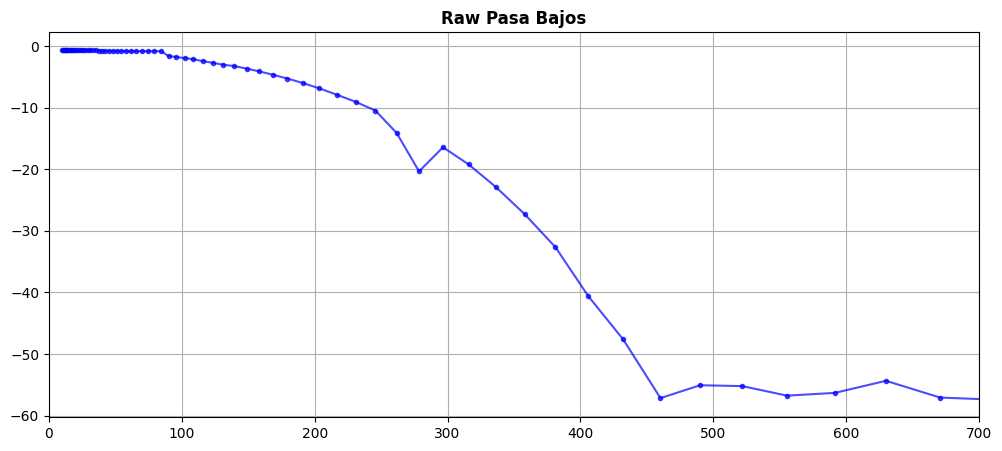

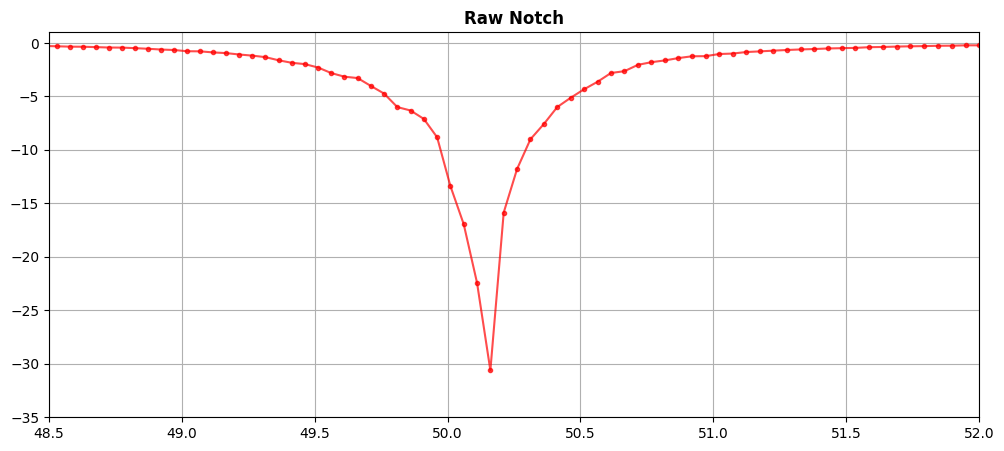

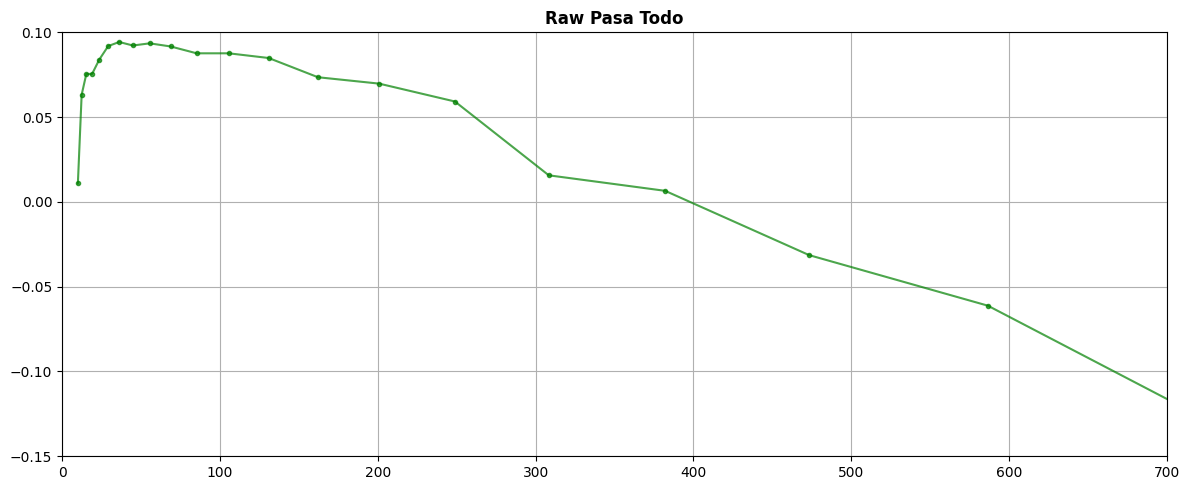

In [78]:
fig, (ax0) = plt.subplots(1, 1, figsize=(12, 5))
fig, (ax1) = plt.subplots(1, 1, figsize=(12, 5))
fig, (ax2) = plt.subplots(1, 1, figsize=(12, 5))

# LP
ax0.plot(f[LP], ch1[LP], 'b', alpha=0.7, marker='.')
ax0.set_xlim(0, 700)
ax0.set_title('Raw Pasa Bajos', fontsize=12, fontweight='bold')
ax0.grid()

# NOTCH
ax1.plot(f[NOTCH], ch1[NOTCH], 'r', alpha=0.7, marker='.')
ax1.set_xlim(48.5, 52)
ax1.set_ylim(-35, 1)
ax1.set_title('Raw Notch', fontsize=12, fontweight='bold')
ax1.grid()

# NONE
ax2.plot(f[NONE], ch1[NONE], 'g', alpha=0.7, marker='.')
ax2.set_xlim(0, 700)
ax2.set_ylim(-0.15, 0.1)
ax2.set_title('Raw Pasa Todo', fontsize=12, fontweight='bold')
ax2.grid()

plt.tight_layout()
plt.show()

 Se interpolo el Pasa Todo, con el fin de que pueda trabajar con el eje de frecuencia tanto del Pasa Bajos como del Notch. 
 Haciendo esto podemos realizar la resta del Pasa Todo para conseguir ambos filtros de forma correcta y sin alteraciones (cabe aclarar que esto se puede hacer debido a que las tres transferencias medidas están en dB, en caso de trabajar en *veces* se debe realizar una división)

 Por ultimo, se la compara con las transferencias de los filtros digitales ideales obtenidas con anterioridad:

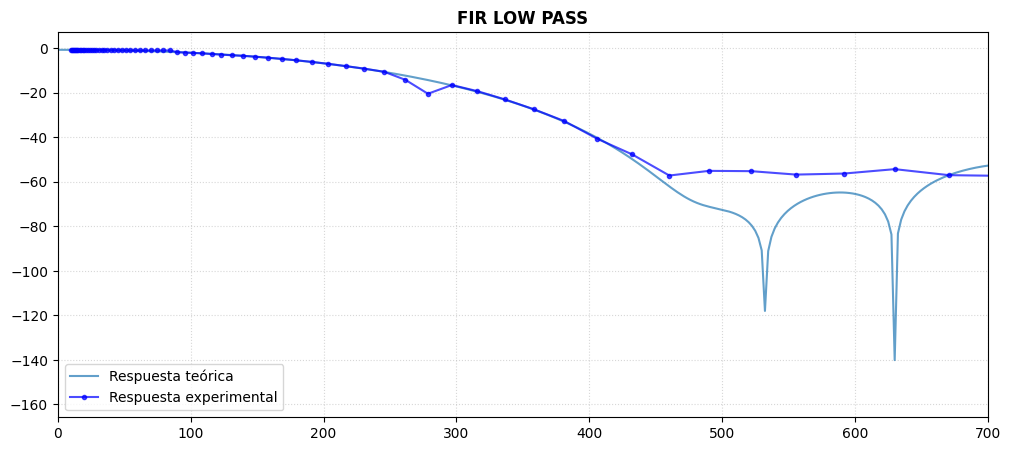

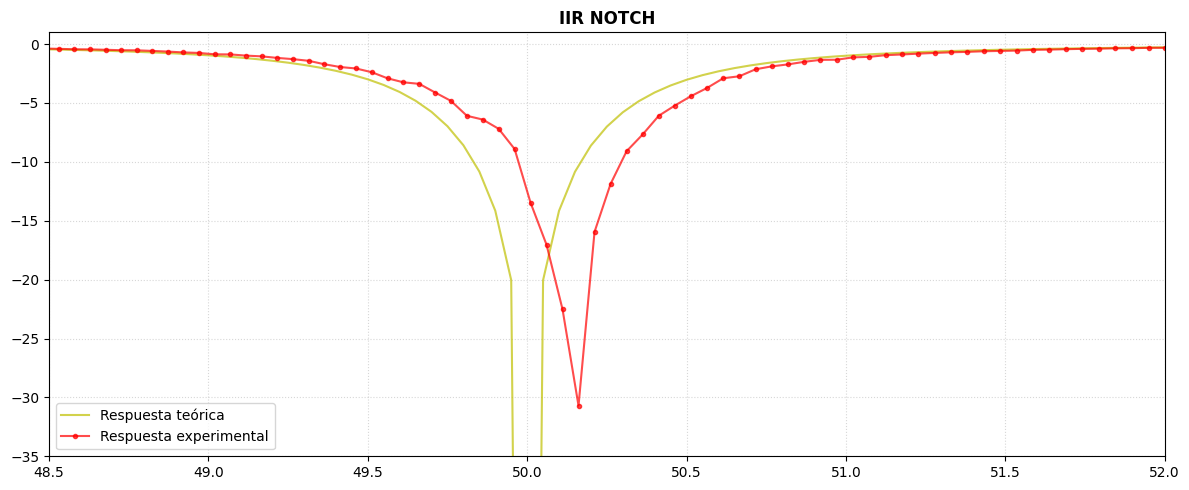

In [79]:
# Interpolamos el Pasa Todo para que se pueda usar el eje de frecuencias del LP y del Notch
NONE_interp  = [ np.interp(f[LP], f[NONE], ch1[NONE]) , np.interp(f[NOTCH], f[NONE], ch1[NONE]) ] # NONE_interp = [ LP , NOTCH ]
LP_interp    = ch1[LP] - NONE_interp[LP]
NOTCH_interp = ch1[NOTCH] - NONE_interp[NOTCH]

#========================================================

fig, (ax0) = plt.subplots(1, 1, figsize=(12, 5))
fig, (ax1) = plt.subplots(1, 1, figsize=(12, 5))

# LP
ax0.plot( ww   , hh_LP    , color='tab:blue', alpha=0.7 , label='Respuesta teórica')
ax0.plot( f[LP], LP_interp, 'b' , alpha=0.7, marker='.' , label='Respuesta experimental')
ax0.set_xlim(0, 700)
ax0.set_title('FIR LOW PASS', fontsize=12, fontweight='bold')
ax0.grid( True, linestyle=':', alpha=0.5)
ax0.legend(loc='lower left', fontsize=10)

# NOTCH
ax1.plot(w, 20*np.log10(np.maximum(np.abs(h), 1e-8)) , 'y', alpha=0.7 , label='Respuesta teórica')
ax1.plot(f[NOTCH], NOTCH_interp, 'r', alpha=0.7, marker='.'           , label='Respuesta experimental')
ax1.set_xlim(48.5, 52)
ax1.set_ylim(-35, 1)
ax1.set_title('IIR NOTCH', fontsize=12, fontweight='bold')
ax1.grid( True, linestyle=':', alpha=0.5)
ax1.legend(loc='lower left', fontsize=10)

plt.tight_layout()
plt.show()

### Conclusiones
 Como se puede observar, el LP se acercó con gran precisión a la respuesta ideal del filtro en la banda de paso (se interpreta que el pequeño pico se debe a ruido durante la medición).

 En cuanto al Notch, los resultados no son perfectos pero lo vuelve un filtro realizable y que pueda ser útil ya que aunque se corrió en frecuencia, si se mira con determinación, se corrió unos 0.25Hz por lo que para ciertas aplicaciones que no requieran una exactutud tan exhaustiva.  En cuanto a la atenuación, se hubiera esperado más atenuación si se lo compara con el real pero en el centro de la banda de parada, solo permite pasar un 3% de la señal (-30dB) por lo que, aunque discrepa en precisión y en atenuación con respecto a la respuesta teórica, puede ser sumamente útil en bastantes aplicaciones.